# Cost-aware gating under extreme class imbalance — experiment notebook (v3)

This notebook produces the evidence for the MLWA manuscript. It answers four questions:

| # | Question | Section |
|---|---|---|
| Q1 | How should the gate's threshold be chosen when positives are rare and imbalance remedies shift the score scale? | 7, 8 |
| Q2 | Which gate (backbone x input resolution x imbalance remedy, incl. one-class gates trained on background only) gives the best speed-up at full recall? | 7, 9 |
| Q3 | What do the gates cost: parameters, FLOPs, CPU and GPU latency, relative to HED? | 5, 6 |
| Q4 | Does the closed-form model S = 1/(rho + q) predict the measured end-to-end speed-up, on CPU and on GPU? | 11 |

**Protocol.** All 309 labelled frames are pooled and evaluated with *recording-grouped*, stratified 5-fold cross-validation repeated over several seeds (no recording appears in both training and test folds). Thresholds are chosen inside each training fold by inner grouped cross-validation under a recall constraint. Gates are linear or one-class heads on frozen ImageNet features, which makes hundreds of fits affordable; the fine-tuned ResNet50 gate of the earlier notebook is re-evaluated in Section 12.

**Run:** `Runtime -> Run all`. Works on a CPU or a GPU runtime; on a GPU runtime the notebook measures **both** CPU and GPU latency. The first cell may install OpenCV 4.12 and restart once (OpenCV 5 cannot read the Caffe HED model). Typical runtime: 30-60 min.

All outputs go to `RESULTS_DIR` (`tables/`, `figures/`, `logs/`, `cache/`, `overleaf/` + `overleaf_v3.zip`, `results_summary_v3.json`).

## 1. Environment

In [ ]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
SMOKE_TEST = os.environ.get("MLWA_SMOKE_TEST", "0") == "1"   # quick dry run only; never for the paper
if IN_COLAB and not SMOKE_TEST:
    from google.colab import drive
    drive.mount("/content/drive")

REQUIRED_OPENCV = "4.12.0.88"
def _opencv_has_caffe():
    try:
        import cv2
        return hasattr(cv2.dnn, "readNetFromCaffe") and hasattr(cv2, "dnn_registerLayer")
    except ImportError:
        return False
if not _opencv_has_caffe():
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "opencv-python", "opencv-contrib-python",
                    "opencv-python-headless", "opencv-contrib-python-headless"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"opencv-python-headless=={REQUIRED_OPENCV}"], check=True)
    print(">>> OpenCV 4.x installed. The runtime restarts now; then choose 'Run all' again. <<<")
    if IN_COLAB:
        os.kill(os.getpid(), 9)
    raise SystemExit("Restart the kernel and run again.")
print("OpenCV with Caffe importer available.")

Mounted at /content/drive
OpenCV with Caffe importer available.


In [ ]:
import json, time, re, platform, shutil, datetime, warnings, itertools
import numpy as np, pandas as pd, cv2, matplotlib, matplotlib.pyplot as plt
import tensorflow as tf, keras
from scipy.optimize import minimize
from scipy.stats import beta
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, LeaveOneGroupOut
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from IPython.display import display
warnings.filterwarnings("ignore", category=UserWarning)

def _sh(cmd):
    try:
        return subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception:
        return ""
def _cpu_model():
    try:
        return next(l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name"))
    except Exception:
        return platform.processor() or "unknown"

GPUS = tf.config.list_physical_devices("GPU")
for g in GPUS:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception:
        pass
ENV = {"timestamp_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
       "python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
       "opencv": cv2.__version__, "numpy": np.__version__, "cpu_model": _cpu_model(), "cpu_logical_cores": os.cpu_count(),
       "gpus": [g.name for g in GPUS], "gpu_model": _sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader"),
       "opencv_cuda_devices": int(cv2.cuda.getCudaEnabledDeviceCount()) if hasattr(cv2, "cuda") else 0,
       "opencv_threads": cv2.getNumThreads(), "in_colab": IN_COLAB, "smoke_test": SMOKE_TEST}
for k, v in ENV.items():
    print(f"{k:>20}: {v}")

       timestamp_utc: 2026-10-17 10:24:00
              python: 3.13.15
          tensorflow: 2.21.0
               keras: 3.13.2
              opencv: 4.14.0
               numpy: 2.1.3
           cpu_model: Intel(R) Xeon(R) CPU @ 2.00GHz
   cpu_logical_cores: 2
                gpus: ['/physical_device:GPU:0']
           gpu_model: Tesla T4, 15360 MiB
 opencv_cuda_devices: 0
      opencv_threads: 2
            in_colab: True
          smoke_test: False


## 2. Configuration
`IMG_SIZE` is (height, width), as in the earlier notebooks. `SCALES` adds reduced input resolutions as a cheap way to lower gate cost.

In [ ]:
BASE_DIR = os.environ.get("MLWA_BASE_DIR", "/content/drive/MyDrive/M2Project")
CONFIG = {
    "DATA_DIRS": [os.path.join(BASE_DIR, d) for d in ("train_resized", "valid_resized", "test_resized")],
    "IMG_SIZE": (300, 146),
    "BACKBONES": ["MobileNetV3Small", "MobileNetV3Large", "EfficientNetB0", "ResNet50"],
    "SCALES": [1.0, 0.5],
    "WEIGHTS": "imagenet",
    "STRATEGIES": ["LR", "LR-weighted", "LR-SMOTE", "Focal-weighted", "OneClass-Mahalanobis", "OneClass-kNN"],
    "FLIP_AUG": True,              # add mirrored training frames to supervised heads
    "C": 1.0,                      # inverse L2 strength of logistic heads
    "FOCAL_GAMMA": 2.0, "FOCAL_ALPHA": 0.25, "FOCAL_L2": 1e-3,
    "PCA_DIM": 32, "KNN_K": 5,
    "RECALL_TARGETS": [1.0, 0.95],
    "N_FOLDS": 5, "INNER_FOLDS": 3, "CV_SEEDS": [0, 1, 2],
    "LEGACY_TAU": 0.35,
    "LAT_WARMUP": 5, "LAT_REPEATS": 50, "HED_REPEATS": 20,
    "HED_PROTOTXT": os.environ.get("MLWA_HED_PROTOTXT", "/content/drive/MyDrive/Holistically-Nested_Edge_Detection/deploy.prototxt"),
    "HED_MODEL": os.environ.get("MLWA_HED_MODEL", "/content/drive/MyDrive/Holistically-Nested_Edge_Detection/hed_pretrained_bsds.caffemodel"),
    "HED_MEAN": (104.00698793, 116.66876762, 122.67891434),
    "LEGACY_V2_TABLES": os.path.join(BASE_DIR, "results_mlwa", "tables"),
    "RESULTS_DIR": os.path.join(BASE_DIR, "results_mlwa_v3"),
    "SEED": 1337,
}
if SMOKE_TEST:
    CONFIG.update({"WEIGHTS": None, "CV_SEEDS": [0], "LAT_REPEATS": 3, "HED_REPEATS": 2, "LAT_WARMUP": 1,
                   "BACKBONES": ["MobileNetV3Small", "ResNet50"]})

RD = CONFIG["RESULTS_DIR"]
DIRS = {k: os.path.join(RD, k) for k in ["tables", "figures", "logs", "cache", "overleaf"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)
json.dump(CONFIG, open(os.path.join(DIRS["logs"], "config.json"), "w"), indent=2)
json.dump(ENV, open(os.path.join(DIRS["logs"], "environment.json"), "w"), indent=2)
keras.utils.set_random_seed(CONFIG["SEED"])

RESULTS = {}
def record(k, v):
    RESULTS[k] = v
def save_table(df, name, show=True, index=False):
    df.to_csv(os.path.join(DIRS["tables"], f"{name}.csv"), index=index)
    if show:
        display(df)
    print(f"[saved] tables/{name}.csv")
def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(DIRS["figures"], f"{name}.{ext}"), dpi=300, bbox_inches="tight")
    print(f"[saved] figures/{name}.png/.pdf")
def clopper_pearson(k, n, a=0.05):
    if n == 0:
        return (np.nan, np.nan)
    return (0.0 if k == 0 else float(beta.ppf(a / 2, k, n - k + 1)), 1.0 if k == n else float(beta.ppf(1 - a / 2, k + 1, n - k)))
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

## 3. Data: pool all labelled frames, derive recording and station groups
File names look like `img_<station>_<recording>_<frame>.jpg`. A *recording* is `<station>_<recording>`; it is the grouping unit for cross-validation. The original train/val/test split is kept for reference only.

In [ ]:
def load_dir(d):
    ds = tf.keras.utils.image_dataset_from_directory(d, label_mode="binary", image_size=CONFIG["IMG_SIZE"],
                                                     batch_size=32, shuffle=False)
    X = np.concatenate([x.numpy() for x, _ in ds]).astype(np.float32)
    y = np.concatenate([t.numpy() for _, t in ds]).astype(int).ravel()
    return X, y, list(ds.file_paths), list(ds.class_names)

parts = [load_dir(d) for d in CONFIG["DATA_DIRS"]]
X = np.concatenate([p[0] for p in parts]); y = np.concatenate([p[1] for p in parts])
paths = sum([p[2] for p in parts], [])
orig_split = np.concatenate([[s] * len(p[1]) for s, p in zip(["train", "valid", "test"], parts)])
print("class folders:", parts[0][3], "-> label 1 = joint")

NAME_RE = re.compile(r"img_(\d+)_(\d+)_(\d+)")
def parse(p):
    m = NAME_RE.search(os.path.basename(p))
    return (f"{m.group(1)}_{m.group(2)}", m.group(1), int(m.group(3))) if m else (os.path.basename(p), "unknown", -1)
meta = pd.DataFrame([parse(p) for p in paths], columns=["recording", "station", "frame_no"])
meta["file"] = [os.path.basename(p) for p in paths]; meta["label"] = y; meta["orig_split"] = orig_split
groups, stations = meta.recording.values, meta.station.values
save_table(meta, "frames", show=False)

summary = pd.DataFrame({
    "frames": [len(y)], "joints": [int(y.sum())], "background": [int((y == 0).sum())],
    "joint_rate_%": [round(100 * y.mean(), 1)], "recordings": [meta.recording.nunique()],
    "recordings_with_joints": [meta[meta.label == 1].recording.nunique()], "stations": [meta.station.nunique()]})
save_table(summary, "dataset_summary")
st = meta.groupby("station").label.agg(frames="size", joints="sum").reset_index()
save_table(st, "frames_per_station")
PI = float(y.mean())
record("dataset", summary.iloc[0].to_dict()); record("pi", PI)

Found 213 files belonging to 2 classes.
Found 85 files belonging to 2 classes.
Found 11 files belonging to 2 classes.
class folders: ['no', 'yes'] -> label 1 = joint
[saved] tables/frames.csv


,frames,joints,background,joint_rate_%,recordings,recordings_with_joints,stations
0,309,29,280,9.4,80,29,7


[saved] tables/dataset_summary.csv


,station,frames,joints
0,01,179,5
1,02,80,5
2,03,2,0
3,05,5,5
4,06,7,7
5,08,7,7
6,unknown,29,0


[saved] tables/frames_per_station.csv


## 4. Frozen ImageNet features (cached)
For every backbone and input scale: global-average-pooled features of each frame and of its horizontal mirror.

In [ ]:
BACKBONES = {
    "MobileNetV3Small": (tf.keras.applications.MobileNetV3Small, lambda x: x),           # rescaling is built in
    "MobileNetV3Large": (tf.keras.applications.MobileNetV3Large, lambda x: x),
    "EfficientNetB0":   (tf.keras.applications.EfficientNetB0, lambda x: x),
    "ResNet50":         (tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input),
}
def input_shape(scale):
    h, w = CONFIG["IMG_SIZE"]
    return (max(32, int(round(h * scale))), max(32, int(round(w * scale))), 3)

def build_extractor(name, scale):
    ctor, prep = BACKBONES[name]
    shp = input_shape(scale)
    inp = keras.Input(shape=shp)
    kw = dict(input_shape=shp, include_top=False, weights=CONFIG["WEIGHTS"], pooling="avg")
    if name.startswith("MobileNetV3"):
        kw["include_preprocessing"] = True
    base = ctor(**kw)
    return keras.Model(inp, base(prep(inp)), name=f"{name}_{scale}")

def resize_batch(Xb, scale):
    return Xb if scale == 1.0 else tf.image.resize(Xb, input_shape(scale)[:2], method="bilinear").numpy()

def make_fwd(model):
    @tf.autograph.experimental.do_not_convert
    def _f(x):
        return model(x, training=False)
    return tf.function(_f, reduce_retracing=True)

CONFIGS = [(b, s) for b in CONFIG["BACKBONES"] for s in CONFIG["SCALES"]]
FEATS = {}
for b, s in CONFIGS:
    cache = os.path.join(DIRS["cache"], f"feat_{b}_{s}.npz")
    if os.path.exists(cache) and not SMOKE_TEST:
        z = np.load(cache); FEATS[(b, s)] = (z["f"], z["f_flip"]); continue
    t0 = time.time()
    m = build_extractor(b, s)
    f_ = make_fwd(m)
    Xs = resize_batch(X, s)
    f = np.concatenate([f_(tf.constant(Xs[i:i + 16])).numpy() for i in range(0, len(Xs), 16)])
    ff = np.concatenate([f_(tf.constant(Xs[i:i + 16, :, ::-1])).numpy() for i in range(0, len(Xs), 16)])
    np.savez_compressed(cache, f=f, f_flip=ff); FEATS[(b, s)] = (f, ff)
    print(f"{b} @ {s}: features {f.shape} in {time.time() - t0:.0f}s")
    keras.backend.clear_session()

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV3Small @ 1.0: features (309, 576) in 9s
MobileNetV3Small @ 0.5: features (309, 576) in 5s
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV3Large @ 1.0: features (309, 960) in 8s
MobileNetV3Large @ 0.5: features (309, 960) in 5s
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0 @ 1.0: features (309, 1280) in 11s
EfficientNetB0 @ 0.5: features (309, 1280) in 7s
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
ResNet50 @ 1.0: features (309, 2048) in 15s
ResNet50 @ 0.5: features (309, 2048) in 7s


## 5. Computational complexity
Parameters and FLOPs (1 multiply-add = 2 FLOPs) of each gate backbone at batch size 1, and of HED (OpenCV `getFLOPS`).

In [ ]:
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
def count_flops(model, shape):
    @tf.autograph.experimental.do_not_convert
    def fwd(x):
        return model(x, training=False)
    cf = tf.function(fwd).get_concrete_function(tf.TensorSpec([1, *shape], tf.float32))
    g = convert_variables_to_constants_v2(cf).graph
    opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation(); opts["output"] = "none"
    return tf.compat.v1.profiler.profile(graph=g, run_meta=tf.compat.v1.RunMetadata(), cmd="op", options=opts).total_float_ops

# --- HED (Caffe, OpenCV DNN) ---
class CropLayer(object):
    def __init__(self, params, blobs):
        self.ys = self.xs = self.h = self.w = 0
    def getMemoryShapes(self, inputs):
        i, t = inputs[0], inputs[1]
        self.ys, self.xs, self.h, self.w = int((i[2] - t[2]) / 2), int((i[3] - t[3]) / 2), t[2], t[3]
        return [[i[0], i[1], t[2], t[3]]]
    def forward(self, inputs):
        return [inputs[0][:, :, self.ys:self.ys + self.h, self.xs:self.xs + self.w]]
for p in (CONFIG["HED_PROTOTXT"], CONFIG["HED_MODEL"]):
    if not os.path.exists(p):
        raise FileNotFoundError(f"HED file missing: {p}")
try:
    cv2.dnn_unregisterLayer("Crop")
except Exception:
    pass
cv2.dnn_registerLayer("Crop", CropLayer)
def load_hed(cuda=False):
    net = cv2.dnn.readNetFromCaffe(CONFIG["HED_PROTOTXT"], CONFIG["HED_MODEL"])
    if cuda:
        net.setPreferableBackend(cv2.dnn.DNN_BACKEND_CUDA); net.setPreferableTarget(cv2.dnn.DNN_TARGET_CUDA)
    else:
        net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV); net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
    return net
hed = load_hed()
H, W = CONFIG["IMG_SIZE"]
def hed_forward(net, bgr):
    net.setInput(cv2.dnn.blobFromImage(bgr, 1.0, (bgr.shape[1], bgr.shape[0]), CONFIG["HED_MEAN"], swapRB=False, crop=False))
    return net.forward()
hed_flops = float(hed.getFLOPS([1, 3, H, W]))

rows = []
for b, s in CONFIGS:
    m = build_extractor(b, s)
    try:
        fl = count_flops(m, input_shape(s))
    except Exception as e:
        print("FLOP count failed for", b, s, e); fl = np.nan
    rows.append({"gate": b, "scale": s, "input": "x".join(map(str, input_shape(s)[:2])), "params_M": m.count_params() / 1e6,
                 "feature_dim": int(m.output_shape[-1]), "GFLOPs": fl / 1e9, "GFLOPs_rel_HED": fl / hed_flops})
    keras.backend.clear_session()
cx = pd.DataFrame(rows)
cx = pd.concat([cx, pd.DataFrame([{"gate": "HED (stage 2)", "scale": 1.0, "input": f"{H}x{W}", "params_M": np.nan,
                                    "feature_dim": np.nan, "GFLOPs": hed_flops / 1e9, "GFLOPs_rel_HED": 1.0}])], ignore_index=True)
save_table(cx.round(4), "complexity")
record("complexity", cx.to_dict(orient="records"))

Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


,gate,scale,input,params_M,feature_dim,GFLOPs,GFLOPs_rel_HED
0,MobileNetV3Small,1.0,300x146,0.9391,576.0,0.1114,0.0023
1,MobileNetV3Small,0.5,150x73,0.9391,576.0,0.0312,0.0006
2,MobileNetV3Large,1.0,300x146,2.9964,960.0,0.4225,0.0087
3,MobileNetV3Large,0.5,150x73,2.9964,960.0,0.1164,0.0024
4,EfficientNetB0,1.0,300x146,4.0496,1280.0,0.7685,0.0158
5,EfficientNetB0,0.5,150x73,4.0496,1280.0,0.2118,0.0043
6,ResNet50,1.0,300x146,23.5877,2048.0,7.3589,0.1510
7,ResNet50,0.5,150x73,23.5877,2048.0,1.9862,0.0408
8,HED (stage 2),1.0,300x146,NaN,NaN,48.7237,1.0000


[saved] tables/complexity.csv


## 6. Latency: CPU and GPU
Batch size 1 (one frame at a time, as in streaming), after warm-up. Each gate = backbone + linear head (the head adds a negligible dot product). GPU timings include the host-to-device copy and the result read-back. HED runs in OpenCV DNN on the CPU; OpenCV's CUDA backend is used only if the installed OpenCV has CUDA support (pip wheels do not).

,model,scale,device,mean_ms,median_ms,sd_ms,rho
0,HED,1.0,CPU,476.2839,427.9482,174.1641,1.0000
1,MobileNetV3Small,1.0,CPU,12.5921,12.1142,1.7525,0.0264
2,MobileNetV3Small,1.0,GPU,6.4814,6.3818,0.4563,0.0136
3,MobileNetV3Small,0.5,CPU,4.8744,4.8918,0.1498,0.0102
4,MobileNetV3Small,0.5,GPU,6.1970,6.1521,0.2805,0.0130
5,MobileNetV3Large,1.0,CPU,30.4891,28.4324,5.6689,0.0640
6,MobileNetV3Large,1.0,GPU,7.3691,7.3433,0.2527,0.0155
7,MobileNetV3Large,0.5,CPU,10.0207,9.9665,0.4918,0.0210
8,MobileNetV3Large,0.5,GPU,7.5350,7.2279,1.1581,0.0158
9,EfficientNetB0,1.0,CPU,52.6184,51.4736,4.5917,0.1105


[saved] tables/latency_cpu_gpu.csv
[saved] figures/fig_latency_cpu_gpu.png/.pdf


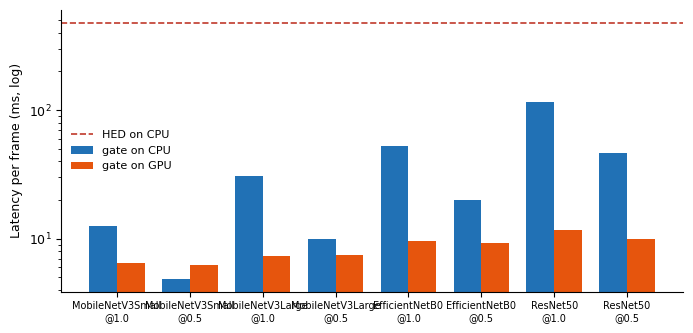

In [ ]:
DEVICES = ["CPU"] + (["GPU"] if GPUS else [])
def time_calls(fn, arg, warmup, reps):
    for _ in range(warmup):
        fn(arg)
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(arg); ts.append(time.perf_counter() - t)
    return np.array(ts)

x1 = X[:1]
bgr1 = cv2.cvtColor(np.clip(X[0], 0, 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
lat_rows = []
t_hed = time_calls(lambda a: hed_forward(hed, a), bgr1, CONFIG["LAT_WARMUP"], CONFIG["HED_REPEATS"])
lat_rows.append({"model": "HED", "scale": 1.0, "device": "CPU", "mean_ms": 1e3 * t_hed.mean(),
                 "median_ms": 1e3 * np.median(t_hed), "sd_ms": 1e3 * t_hed.std()})
if ENV["opencv_cuda_devices"] > 0:
    hed_gpu = load_hed(cuda=True)
    t = time_calls(lambda a: hed_forward(hed_gpu, a), bgr1, CONFIG["LAT_WARMUP"], CONFIG["HED_REPEATS"])
    lat_rows.append({"model": "HED", "scale": 1.0, "device": "GPU", "mean_ms": 1e3 * t.mean(),
                     "median_ms": 1e3 * np.median(t), "sd_ms": 1e3 * t.std()})
L_HED = t_hed.mean()

for b, s in CONFIGS:
    xs = resize_batch(x1, s)
    for dev in DEVICES:
        with tf.device(f"/{dev}:0"):
            m = build_extractor(b, s)
            w_head = np.random.randn(m.output_shape[-1]).astype(np.float32)
            fwd = make_fwd(m)
            def gate(a, fwd=fwd):
                return float(fwd(tf.constant(a)).numpy()[0] @ w_head)    # .numpy() forces device sync
            t = time_calls(gate, xs, CONFIG["LAT_WARMUP"], CONFIG["LAT_REPEATS"])
        lat_rows.append({"model": b, "scale": s, "device": dev, "mean_ms": 1e3 * t.mean(),
                         "median_ms": 1e3 * np.median(t), "sd_ms": 1e3 * t.std()})
        keras.backend.clear_session()
lat = pd.DataFrame(lat_rows)
lat["rho"] = lat.mean_ms / (1e3 * L_HED)          # gate cost relative to HED on the CPU
save_table(lat.round(4), "latency_cpu_gpu")
record("latency", lat.to_dict(orient="records")); record("L_HED_cpu_s", float(L_HED))

def rho_of(b, s, dev):
    r = lat[(lat.model == b) & (lat.scale == s) & (lat.device == dev)]
    return float(r.rho.iloc[0]) if len(r) else np.nan

fig, ax = plt.subplots(figsize=(7, 3.4))
lab = [f"{b}\n@{s}" for b, s in CONFIGS]; xpos = np.arange(len(CONFIGS)); wd = 0.38
for k, (dev, col) in enumerate(zip(DEVICES, ["#2171b5", "#e6550d"])):
    vals = [lat[(lat.model == b) & (lat.scale == s) & (lat.device == dev)].mean_ms.iloc[0] for b, s in CONFIGS]
    ax.bar(xpos + (k - (len(DEVICES) - 1) / 2) * wd, vals, wd, color=col, label=f"gate on {dev}")
ax.axhline(1e3 * L_HED, color="#c0392b", ls="--", lw=1.2, label="HED on CPU")
ax.set_yscale("log"); ax.set_ylabel("Latency per frame (ms, log)"); ax.set_xticks(xpos); ax.set_xticklabels(lab, fontsize=7)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save_fig(fig, "fig_latency_cpu_gpu"); plt.show()

## 7. Gate heads and imbalance remedies
All heads produce a score where larger means *joint*.

| Strategy | Training data | Imbalance handling |
|---|---|---|
| LR | both classes | none (plain logistic regression) |
| LR-weighted | both classes | inverse-frequency class weights |
| LR-SMOTE | both classes | SMOTE oversampling of joints in feature space |
| Focal-weighted | both classes | focal loss (gamma = 2, alpha = 0.25) + class weights, i.e. the loss of the original gate |
| OneClass-Mahalanobis | background only (+ mirrored background) | Gaussian model of background features (PCA + Ledoit-Wolf), score = Mahalanobis distance |
| OneClass-kNN | background only (+ mirrored background) | mean cosine distance to the k nearest background frames |

In [ ]:
def _sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -50, 50)))

class FocalLogistic:
    # Linear model trained with the weighted binary focal loss of the paper (Eq. 4), L-BFGS
    def __init__(self, gamma, alpha, l2, class_weight):
        self.g, self.a, self.l2, self.cw = gamma, alpha, l2, class_weight
    def fit(self, Xf, yf):
        n, d = Xf.shape
        s = np.where(yf == 1, 1.0, -1.0)
        at = np.where(yf == 1, self.a, 1 - self.a) * np.where(yf == 1, self.cw[1], self.cw[0])
        def fg(theta):
            w, b = theta[:d], theta[d]
            z = Xf @ w + b
            pt = np.clip(_sigmoid(s * z), 1e-7, 1 - 1e-7)
            loss = np.sum(-at * (1 - pt) ** self.g * np.log(pt)) / n + self.l2 * w @ w
            dz = at * s * (1 - pt) ** self.g * (self.g * pt * np.log(pt) - (1 - pt)) / n
            return loss, np.r_[Xf.T @ dz + 2 * self.l2 * w, dz.sum()]
        r = minimize(fg, np.zeros(d + 1), jac=True, method="L-BFGS-B", options={"maxiter": 500})
        self.w, self.b = r.x[:d], r.x[d]
        return self
    def score(self, Xf):
        return _sigmoid(Xf @ self.w + self.b)

def smote(Xp, n_new, k, rng):
    if len(Xp) < 2 or n_new <= 0:
        return np.empty((0, Xp.shape[1]))
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(Xp))).fit(Xp)
    idx = nn.kneighbors(Xp, return_distance=False)[:, 1:]
    i = rng.integers(0, len(Xp), n_new); j = idx[i, rng.integers(0, idx.shape[1], n_new)]
    return Xp[i] + rng.random((n_new, 1)) * (Xp[j] - Xp[i])

class Head:
    def __init__(self, strategy, seed=0):
        self.st, self.seed = strategy, seed
    def fit(self, F, Fflip, yy):
        st = self.st
        one_class = st.startswith("OneClass")
        Ftr, ytr = F, yy
        if CONFIG["FLIP_AUG"] and Fflip is not None:          # mirrored frames (for one-class: mirrored background)
            Ftr, ytr = np.vstack([F, Fflip]), np.r_[yy, yy]
        self.sc = StandardScaler().fit(Ftr[ytr == 0] if one_class else Ftr)
        Z = self.sc.transform(Ftr)
        n0, n1 = (ytr == 0).sum(), max((ytr == 1).sum(), 1)
        cw = {0: len(ytr) / (2 * n0), 1: len(ytr) / (2 * n1)}
        if st == "LR":
            self.m = LogisticRegression(C=CONFIG["C"], max_iter=5000).fit(Z, ytr)
        elif st == "LR-weighted":
            self.m = LogisticRegression(C=CONFIG["C"], max_iter=5000, class_weight="balanced").fit(Z, ytr)
        elif st == "LR-SMOTE":
            rng = np.random.default_rng(self.seed)
            Zs = smote(Z[ytr == 1], int(n0 - (ytr == 1).sum()), 5, rng)
            self.m = LogisticRegression(C=CONFIG["C"], max_iter=5000).fit(np.vstack([Z, Zs]), np.r_[ytr, np.ones(len(Zs), int)])
        elif st == "Focal-weighted":
            self.m = FocalLogistic(CONFIG["FOCAL_GAMMA"], CONFIG["FOCAL_ALPHA"], CONFIG["FOCAL_L2"], cw).fit(Z, ytr)
        elif st == "OneClass-Mahalanobis":
            Zn = Z[ytr == 0]
            self.pca = PCA(n_components=min(CONFIG["PCA_DIM"], len(Zn) - 1, Zn.shape[1]), random_state=0).fit(Zn)
            self.lw = LedoitWolf().fit(self.pca.transform(Zn))
        elif st == "OneClass-kNN":
            Zn = Z[ytr == 0]; Zn = Zn / (np.linalg.norm(Zn, axis=1, keepdims=True) + 1e-8)
            self.nn = NearestNeighbors(n_neighbors=min(CONFIG["KNN_K"], len(Zn)), metric="cosine").fit(Zn)
        return self
    def score(self, F):
        Z = self.sc.transform(F)
        if self.st in ("LR", "LR-weighted", "LR-SMOTE"):
            return self.m.predict_proba(Z)[:, 1]
        if self.st == "Focal-weighted":
            return self.m.score(Z)
        if self.st == "OneClass-Mahalanobis":
            return self.lw.mahalanobis(self.pca.transform(Z))
        Zn = Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-8)
        return self.nn.kneighbors(Zn)[0].mean(axis=1)

## 8. Recall-constrained threshold selection and grouped cross-validation
For a recall target r*, the threshold is chosen **inside the training fold**: inner grouped cross-validation gives out-of-fold scores, and tau is the largest threshold that keeps inner recall >= r* (placed midway to the next lower background score for a margin). The model is then refit on the whole training fold and applied to the test fold.

For each configuration we report, pooled over the test folds of one repetition (mean +- SD over repetitions):
- **PR-AUC**, ROC-AUC, and the threshold-free **FPR at 100% recall** (the share of background frames scoring at least as high as the lowest joint),
- with the selected tau: achieved **recall**, **FPR**, the share **q** of frames routed to HED, and the predicted speed-up **S = 1/(rho + q)** for the gate on CPU and on GPU,
- for supervised heads also the fixed thresholds 0.5 and the legacy 0.35.

In [ ]:
def select_tau(scores, labels, r_target):
    pos = np.sort(scores[labels == 1])
    if len(pos) == 0:
        return np.inf
    k = int(np.floor((1 - r_target) * len(pos) + 1e-9))
    t_pos = pos[min(k, len(pos) - 1)]
    lower = scores[(labels == 0) & (scores < t_pos)]
    return 0.5 * (t_pos + lower.max()) if len(lower) else t_pos

def fpr_at_recall(scores, labels, r=1.0):
    pos = np.sort(scores[labels == 1])
    if len(pos) == 0:
        return np.nan
    t = pos[int(np.floor((1 - r) * len(pos) + 1e-9))]
    return float((scores[labels == 0] >= t).mean())

def splitter(kind, n_splits, seed):
    if kind == "group":
        return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

def run_cv(b, s, strat, seed, kind="group", outer=None):
    F, Ff = FEATS[(b, s)]
    oof = np.full(len(y), np.nan); oof_flip = np.full(len(y), np.nan)
    taus = {r: np.full(len(y), np.nan) for r in CONFIG["RECALL_TARGETS"]}
    outer = outer or splitter(kind, CONFIG["N_FOLDS"], seed)
    split_iter = outer.split(F, y, groups) if not isinstance(outer, LeaveOneGroupOut) else outer.split(F, y, stations)
    for tr, te in split_iter:
        inner = splitter(kind, CONFIG["INNER_FOLDS"], seed + 100)
        inner_sc = np.full(len(tr), np.nan)
        try:
            for itr, ite in inner.split(F[tr], y[tr], groups[tr]):
                if y[tr][itr].sum() == 0:
                    continue
                h = Head(strat, seed).fit(F[tr][itr], Ff[tr][itr], y[tr][itr])
                inner_sc[ite] = h.score(F[tr][ite])
        except ValueError:
            pass
        ok = ~np.isnan(inner_sc)
        h = Head(strat, seed).fit(F[tr], Ff[tr], y[tr])
        oof[te] = h.score(F[te]); oof_flip[te] = h.score(Ff[te])
        for r in CONFIG["RECALL_TARGETS"]:
            taus[r][te] = select_tau(inner_sc[ok], y[tr][ok], r) if ok.any() else np.nan
    return oof, oof_flip, taus

def summarize(oof, oof_flip, taus, b, s, strat):
    out = {"pr_auc": average_precision_score(y, oof), "roc_auc": roc_auc_score(y, oof),
           "fpr_at_r100": fpr_at_recall(oof, y, 1.0), "fpr_at_r95": fpr_at_recall(oof, y, 0.95)}
    def dec_stats(dec, tag):
        tp, fp = int((dec & (y == 1)).sum()), int((dec & (y == 0)).sum())
        out[f"recall_{tag}"] = tp / y.sum(); out[f"fpr_{tag}"] = fp / (y == 0).sum(); q = dec.mean(); out[f"q_{tag}"] = q
        for dev in DEVICES:
            out[f"S_{dev}_{tag}"] = 1 / (rho_of(b, s, dev) + q)
    for r, t in taus.items():
        dec = oof >= t
        dec_stats(dec, f"r{int(r * 100)}")
        if r == 1.0:
            out["recall_mirror_r100"] = float(((oof_flip >= t) & (y == 1)).sum() / y.sum())
            out["fpr_mirror_r100"] = float(((oof_flip >= t) & (y == 0)).sum() / (y == 0).sum())
    if not strat.startswith("OneClass"):
        dec_stats(oof >= 0.5, "t050"); dec_stats(oof >= CONFIG["LEGACY_TAU"], "t035")
    return out

In [ ]:
cv_rows, OOF = [], {}
t0 = time.time()
for (b, s), strat in itertools.product(CONFIGS, CONFIG["STRATEGIES"]):
    for seed in CONFIG["CV_SEEDS"]:
        oof, oof_flip, taus = run_cv(b, s, strat, seed, "group")
        OOF[(b, s, strat, seed)] = (oof, oof_flip, taus)
        cv_rows.append({"gate": b, "scale": s, "strategy": strat, "seed": seed, **summarize(oof, oof_flip, taus, b, s, strat)})
    print(f"{b}@{s} {strat}: done ({time.time() - t0:.0f}s)")
cv = pd.DataFrame(cv_rows)
cv.to_csv(os.path.join(DIRS["tables"], "cv_grouped_per_seed.csv"), index=False)
num = [c for c in cv.columns if c not in ("gate", "scale", "strategy", "seed")]
cv_mean = cv.groupby(["gate", "scale", "strategy"])[num].mean()
cv_sd = cv.groupby(["gate", "scale", "strategy"])[num].std().fillna(0)
cv_mean.round(4).to_csv(os.path.join(DIRS["tables"], "cv_grouped_mean.csv"))
cv_sd.round(4).to_csv(os.path.join(DIRS["tables"], "cv_grouped_sd.csv"))
show_cols = ["pr_auc", "fpr_at_r100", "recall_r100", "fpr_r100", "q_r100", "S_CPU_r100"] + (["S_GPU_r100"] if "GPU" in DEVICES else [])
display(cv_mean[show_cols].round(3).sort_values("S_CPU_r100", ascending=False))

MobileNetV3Small@1.0 LR: done (2s)
MobileNetV3Small@1.0 LR-weighted: done (4s)
MobileNetV3Small@1.0 LR-SMOTE: done (11s)
MobileNetV3Small@1.0 Focal-weighted: done (15s)
MobileNetV3Small@1.0 OneClass-Mahalanobis: done (20s)
MobileNetV3Small@1.0 OneClass-kNN: done (21s)
MobileNetV3Small@0.5 LR: done (23s)
MobileNetV3Small@0.5 LR-weighted: done (25s)
MobileNetV3Small@0.5 LR-SMOTE: done (33s)
MobileNetV3Small@0.5 Focal-weighted: done (37s)
MobileNetV3Small@0.5 OneClass-Mahalanobis: done (43s)
MobileNetV3Small@0.5 OneClass-kNN: done (45s)
MobileNetV3Large@1.0 LR: done (51s)
MobileNetV3Large@1.0 LR-weighted: done (57s)
MobileNetV3Large@1.0 LR-SMOTE: done (66s)
MobileNetV3Large@1.0 Focal-weighted: done (75s)
MobileNetV3Large@1.0 OneClass-Mahalanobis: done (82s)
MobileNetV3Large@1.0 OneClass-kNN: done (83s)
MobileNetV3Large@0.5 LR: done (89s)
MobileNetV3Large@0.5 LR-weighted: done (95s)
MobileNetV3Large@0.5 LR-SMOTE: done (104s)
MobileNetV3Large@0.5 Focal-weighted: done (113s)
MobileNetV3Large

pr_auc  fpr_at_r100  recall_r100  \
gate             scale strategy                                                 
EfficientNetB0   0.5   LR-SMOTE               0.999        0.004        0.977   
                       LR                     1.000        0.000        0.977   
                       LR-weighted            1.000        0.001        1.000   
MobileNetV3Small 1.0   LR                     0.991        0.024        0.966   
                       LR-SMOTE               0.993        0.023        0.977   
                       LR-weighted            0.993        0.020        0.977   
EfficientNetB0   0.5   Focal-weighted         1.000        0.000        0.989   
MobileNetV3Small 1.0   Focal-weighted         0.994        0.021        0.977   
MobileNetV3Large 0.5   OneClass-kNN           0.722        0.155        0.920   
EfficientNetB0   1.0   LR-SMOTE               1.000        0.001        0.989   
                       LR                     1.000        0.001        0.989   
                       LR-weighted            1.000        0.001        1.000   
                       Focal-weighted         1.000        0.000        1.000   
                 0.5   OneClass-kNN           0.867        0.368        0.885   
MobileNetV3Large 1.0   OneClass-kNN           0.872        0.207        0.908   
EfficientNetB0   1.0   OneClass-kNN           0.930        0.187        0.897   
MobileNetV3Large 1.0   LR                     0.971        0.448        0.966   
                       LR-SMOTE               0.974        0.381        0.977   
ResNet50         0.5   LR                     0.992        0.013        1.000   
                       LR-SMOTE               0.992        0.012        1.000   
MobileNetV3Large 1.0   LR-weighted            0.976        0.267        0.966   
ResNet50         0.5   LR-weighted            0.992        0.013        1.000   
                       OneClass-Mahalanobis   0.879        0.071        0.989   
MobileNetV3Large 1.0   Focal-weighted         0.977        0.365        0.966   
ResNet50         0.5   Focal-weighted         0.992        0.013        1.000   
MobileNetV3Small 0.5   OneClass-kNN           0.439        0.415        0.851   
ResNet50         0.5   OneClass-kNN           0.363        0.386        0.931   
MobileNetV3Large 0.5   LR                     0.943        0.998        0.966   
MobileNetV3Small 1.0   OneClass-kNN           0.819        0.485        0.920   
MobileNetV3Large 0.5   Focal-weighted         0.948        0.998        0.966   
ResNet50         1.0   LR-SMOTE               0.984        0.029        1.000   
                       LR                     0.985        0.023        1.000   
                       LR-weighted            0.985        0.023        0.989   
                       Focal-weighted         0.985        0.018        1.000   
MobileNetV3Large 0.5   LR-weighted            0.946        0.998        0.966   
                       OneClass-Mahalanobis   0.725        0.850        0.966   
                       LR-SMOTE               0.935        0.999        0.954   
EfficientNetB0   0.5   OneClass-Mahalanobis   0.787        0.400        0.989   
ResNet50         1.0   OneClass-kNN           0.504        0.649        0.885   
MobileNetV3Large 1.0   OneClass-Mahalanobis   0.865        0.649        0.977   
MobileNetV3Small 1.0   OneClass-Mahalanobis   0.875        0.565        0.989   
                 0.5   LR-SMOTE               0.822        0.785        0.943   
                       LR                     0.816        0.796        0.943   
                       LR-weighted            0.810        0.785        0.943   
                       Focal-weighted         0.820        0.765        0.943   
EfficientNetB0   1.0   OneClass-Mahalanobis   0.835        0.485        0.966   
MobileNetV3Small 0.5   OneClass-Mahalanobis   0.343        0.779        1.000   
ResNet50         1.0   OneClass-Mahalanobis   0.717        0.757        0.93

In [ ]:
# --- 8.1 Best configurations -----------------------------------------------------------------
# Rank by achieved recall at the r* = 100% target (rounded), then by predicted CPU speed-up.
rank = cv_mean.assign(rec_round=cv_mean.recall_r100.round(2)).sort_values(["rec_round", "S_CPU_r100"], ascending=False)
BEST = rank.index[0]
best_by_strategy = rank.reset_index().groupby("strategy").head(1).set_index(["gate", "scale", "strategy"])
best_by_gate = rank.reset_index().groupby(["gate", "scale"]).head(1).set_index(["gate", "scale", "strategy"])
REF = ("ResNet50", 1.0, "Focal-weighted") if ("ResNet50", 1.0, "Focal-weighted") in cv_mean.index else rank.index[-1]
print("Best configuration:", BEST, "| reference (original design):", REF)
fmt = lambda m, sd: f"{m:.3f} ± {sd:.3f}"
tbl = []
for idx in list(best_by_gate.index):
    m, sd = cv_mean.loc[idx], cv_sd.loc[idx]
    tbl.append({"gate": idx[0], "scale": idx[1], "best strategy": idx[2],
                **{c: fmt(m[c], sd[c]) for c in show_cols}})
best_tbl = pd.DataFrame(tbl)
save_table(best_tbl, "best_per_gate")
strat_tbl = pd.DataFrame([{"strategy": s_, **{c: fmt(cv_mean.loc[(BEST[0], BEST[1], s_)][c], cv_sd.loc[(BEST[0], BEST[1], s_)][c])
                                                  for c in show_cols + (["recall_t050", "fpr_t050", "recall_t035", "fpr_t035"])
                                                  if c in cv_mean.columns and not np.isnan(cv_mean.loc[(BEST[0], BEST[1], s_)][c])}}
                         for s_ in CONFIG["STRATEGIES"]])
save_table(strat_tbl, "strategies_on_best_gate")
record("best", list(BEST)); record("reference", list(REF))
record("cv_mean", cv_mean.reset_index().to_dict(orient="records"))

Best configuration: ('EfficientNetB0', np.float64(0.5), 'LR-weighted') | reference (original design): ('ResNet50', 1.0, 'Focal-weighted')


,gate,scale,best strategy,pr_auc,fpr_at_r100,recall_r100,fpr_r100,q_r100,S_CPU_r100,S_GPU_r100
0,EfficientNetB0,0.5,LR-weighted,1.000 ± 0.001,0.001 ± 0.002,1.000 ± 0.000,0.004 ± 0.006,0.097 ± 0.006,7.190 ± 0.283,8.591 ± 0.402
1,EfficientNetB0,1.0,Focal-weighted,1.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.094 ± 0.000,4.894 ± 0.000,8.784 ± 0.000
2,ResNet50,0.5,LR,0.992 ± 0.008,0.013 ± 0.011,1.000 ± 0.000,0.249 ± 0.400,0.319 ± 0.363,3.622 ± 2.122,5.583 ± 3.772
3,ResNet50,1.0,LR-SMOTE,0.984 ± 0.003,0.029 ± 0.013,1.000 ± 0.000,0.070 ± 0.039,0.157 ± 0.036,2.520 ± 0.224,5.641 ± 1.107
4,MobileNetV3Small,0.5,OneClass-Mahalanobis,0.343 ± 0.077,0.779 ± 0.037,1.000 ± 0.000,0.870 ± 0.039,0.882 ± 0.036,1.121 ± 0.046,1.118 ± 0.046
5,MobileNetV3Small,1.0,OneClass-Mahalanobis,0.875 ± 0.029,0.565 ± 0.233,0.989 ± 0.020,0.752 ± 0.188,0.775 ± 0.170,1.290 ± 0.294,1.312 ± 0.304
6,MobileNetV3Large,1.0,LR-SMOTE,0.974 ± 0.011,0.381 ± 0.522,0.977 ± 0.020,0.239 ± 0.325,0.309 ± 0.293,3.750 ± 2.030,4.814 ± 2.863
7,MobileNetV3Large,0.5,LR,0.943 ± 0.025,0.998 ± 0.004,0.966 ± 0.000,0.388 ± 0.313,0.442 ± 0.283,2.781 ± 1.624,2.832 ± 1.675


[saved] tables/best_per_gate.csv


,strategy,pr_auc,fpr_at_r100,recall_r100,fpr_r100,q_r100,S_CPU_r100,S_GPU_r100,recall_t050,fpr_t050,recall_t035,fpr_t035
0,LR,1.000 ± 0.000,0.000 ± 0.000,0.977 ± 0.040,0.005 ± 0.008,0.096 ± 0.004,7.242 ± 0.193,8.664 ± 0.275,0.897 ± 0.034,0.000 ± 0.000,0.920 ± 0.020,0.000 ± 0.000
1,LR-weighted,1.000 ± 0.001,0.001 ± 0.002,1.000 ± 0.000,0.004 ± 0.006,0.097 ± 0.006,7.190 ± 0.283,8.591 ± 0.402,0.920 ± 0.020,0.000 ± 0.000,0.954 ± 0.053,0.000 ± 0.000
2,LR-SMOTE,0.999 ± 0.002,0.004 ± 0.006,0.977 ± 0.020,0.004 ± 0.006,0.095 ± 0.005,7.302 ± 0.261,8.751 ± 0.373,0.908 ± 0.040,0.000 ± 0.000,0.977 ± 0.020,0.000 ± 0.000
3,Focal-weighted,1.000 ± 0.000,0.000 ± 0.000,0.989 ± 0.020,0.015 ± 0.016,0.107 ± 0.015,6.758 ± 0.655,7.990 ± 0.910,0.897 ± 0.000,0.000 ± 0.000,0.977 ± 0.040,0.000 ± 0.000
4,OneClass-Mahalanobis,0.787 ± 0.030,0.400 ± 0.047,0.989 ± 0.020,0.582 ± 0.241,0.620 ± 0.220,1.634 ± 0.571,1.702 ± 0.618,NaN,NaN,NaN,NaN
5,OneClass-kNN,0.867 ± 0.006,0.368 ± 0.303,0.885 ± 0.111,0.126 ± 0.041,0.197 ± 0.047,4.288 ± 0.875,4.765 ± 1.080,NaN,NaN,NaN,NaN


[saved] tables/strategies_on_best_gate.csv


## 9. Figures: design space, score scales, PR curves

[saved] figures/fig_design_space.png/.pdf


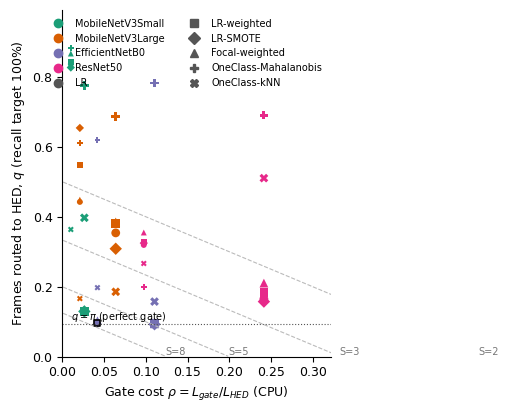

[saved] figures/fig_score_distributions.png/.pdf


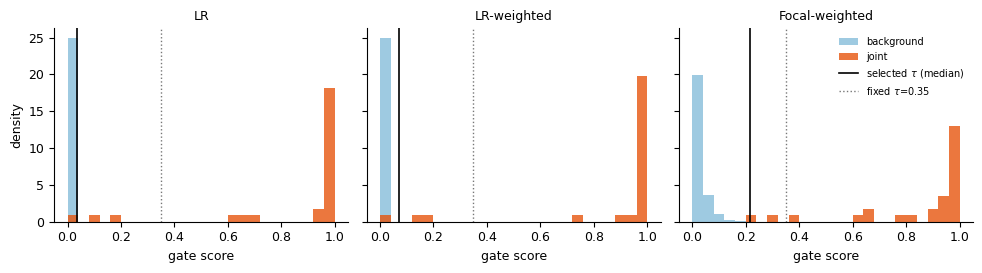

[saved] figures/fig_pr_curves_grouped_cv.png/.pdf


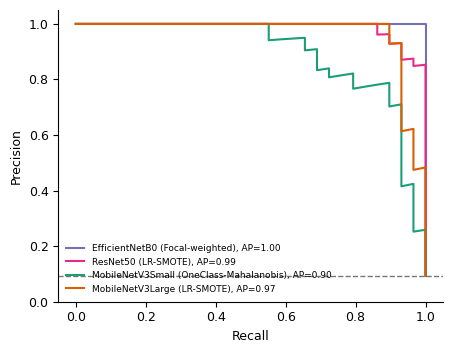

In [ ]:
# --- Pareto: gate cost (rho) vs routed fraction q at r* = 100%, with iso-speed-up curves ---
fig, ax = plt.subplots(figsize=(6.4, 4.2))
markers = {"LR": "o", "LR-weighted": "s", "LR-SMOTE": "D", "Focal-weighted": "^", "OneClass-Mahalanobis": "P", "OneClass-kNN": "X"}
cols = dict(zip(CONFIG["BACKBONES"], ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]))
rr = np.linspace(0.001, 0.8, 300)
for S_ in [2, 3, 5, 8]:
    qq = 1 / S_ - rr; ok = qq > 0
    ax.plot(rr[ok], qq[ok], color="#bbbbbb", lw=0.8, ls="--"); ax.text(rr[ok][-1] if ok.sum() else 0, 0.005, f"S={S_}", fontsize=7, color="#777777")
for (b, s, st_), m in cv_mean.iterrows():
    ax.scatter(rho_of(b, s, "CPU"), m.q_r100, marker=markers[st_], color=cols[b], s=40 if s == 1.0 else 18,
               edgecolor="black" if (b, s, st_) == BEST else "none", lw=1.2)
ax.axhline(PI, color="#555555", lw=0.8, ls=":"); ax.text(0.01, PI, r"$q=\pi$ (perfect gate)", ha="left", va="bottom", fontsize=7)
from matplotlib.lines import Line2D
h1 = [Line2D([], [], color=cols[b], marker="o", ls="", label=b) for b in CONFIG["BACKBONES"]]
h2 = [Line2D([], [], color="#555555", marker=mk, ls="", label=st_) for st_, mk in markers.items()]
ax.legend(handles=h1 + h2, frameon=False, fontsize=7, loc="upper right", ncol=2)
ax.set_xlabel(r"Gate cost $\rho = L_{gate}/L_{HED}$ (CPU)"); ax.set_ylabel(r"Frames routed to HED, $q$ (recall target 100%)")
ax.set_xlim(0, min(1.0, lat[(lat.device == "CPU") & (lat.model != "HED")].rho.max() * 1.25 + 0.02)); ax.set_ylim(0, min(1, cv_mean.q_r100.max() * 1.1 + 0.02))
fig.tight_layout(); save_fig(fig, "fig_design_space"); plt.show()

# --- score scale: the same gate trained with different remedies (repeat 0) ---
b, s, _ = BEST
sel = [st_ for st_ in ["LR", "LR-weighted", "Focal-weighted"] if (b, s, st_, CONFIG["CV_SEEDS"][0]) in OOF]
fig, axes = plt.subplots(1, len(sel), figsize=(3.3 * len(sel), 2.8), sharey=True)
for ax, st_ in zip(np.atleast_1d(axes), sel):
    oof, _, taus = OOF[(b, s, st_, CONFIG["CV_SEEDS"][0])]
    bins = np.linspace(0, 1, 26)
    ax.hist(oof[y == 0], bins=bins, color="#9ecae1", label="background", density=True)
    ax.hist(oof[y == 1], bins=bins, color="#e6550d", alpha=0.8, label="joint", density=True)
    ax.axvline(np.nanmedian(taus[1.0]), color="black", lw=1.2, label=r"selected $\tau$ (median)")
    ax.axvline(CONFIG["LEGACY_TAU"], color="#777777", lw=1, ls=":", label=r"fixed $\tau$=0.35")
    ax.set_title(st_, fontsize=9); ax.set_xlabel("gate score")
np.atleast_1d(axes)[0].set_ylabel("density"); np.atleast_1d(axes)[-1].legend(frameon=False, fontsize=7)
fig.tight_layout(); save_fig(fig, "fig_score_distributions"); plt.show()

# --- PR curves of the best head per backbone (scale 1.0, repeat 0) ---
fig, ax = plt.subplots(figsize=(4.6, 3.6))
for (b_, s_, st_) in best_by_gate.index:
    if s_ != 1.0:
        continue
    oof = OOF[(b_, s_, st_, CONFIG["CV_SEEDS"][0])][0]
    p, r, _ = precision_recall_curve(y, oof)
    ax.plot(r, p, color=cols[b_], lw=1.5, label=f"{b_} ({st_}), AP={average_precision_score(y, oof):.2f}")
ax.axhline(PI, color="#777777", ls="--", lw=1)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=6.5, loc="lower left")
fig.tight_layout(); save_fig(fig, "fig_pr_curves_grouped_cv"); plt.show()

## 10. Robustness: leakage, unseen stations, mirrored frames
* **Leakage:** the best configuration evaluated with ordinary (frame-level) stratified CV versus recording-grouped CV. The difference shows how optimistic a random frame split is.
* **Unseen stations:** leave-one-station-out (the station is the first number in the file name).
* **Mirrored frames:** test folds mirrored horizontally, thresholds unchanged, heads trained with and without flip augmentation.

In [ ]:
rob = []
for cfg_ in dict.fromkeys([BEST, REF]):
    b, s, st_ = cfg_
    for kind in ["frame", "group"]:
        res = [summarize(*run_cv(b, s, st_, sd, kind), b, s, st_) for sd in CONFIG["CV_SEEDS"]]
        rob.append({"config": f"{b}@{s} {st_}", "protocol": f"{kind}-level 5-fold", **pd.DataFrame(res).mean().to_dict()})
    if meta.station.nunique() > 1:
        res = summarize(*run_cv(b, s, st_, CONFIG["CV_SEEDS"][0], "group", outer=LeaveOneGroupOut()), b, s, st_)
        rob.append({"config": f"{b}@{s} {st_}", "protocol": "leave-one-station-out", **res})
rob_df = pd.DataFrame(rob)
save_table(rob_df[["config", "protocol", "pr_auc", "fpr_at_r100", "recall_r100", "fpr_r100", "q_r100", "S_CPU_r100"]].round(3), "robustness_protocols")

mir = []
flip_setting = CONFIG["FLIP_AUG"]
sup = [i for i in rank.index if not i[2].startswith("OneClass")]
BEST_SUP = sup[0] if sup else None
record("best_supervised", list(BEST_SUP) if BEST_SUP else None)
for cfg_ in dict.fromkeys([c for c in (BEST, BEST_SUP) if c]):
    b, s, st_ = cfg_
    for fa in [True, False]:
        CONFIG["FLIP_AUG"] = fa
        res = pd.DataFrame([summarize(*run_cv(b, s, st_, sd, "group"), b, s, st_) for sd in CONFIG["CV_SEEDS"]]).mean()
        mir.append({"config": f"{b}@{s} {st_}", "flip_augmentation": fa, "recall_r100": res.recall_r100, "fpr_r100": res.fpr_r100,
                    "recall_mirrored": res.recall_mirror_r100, "fpr_mirrored": res.fpr_mirror_r100})
CONFIG["FLIP_AUG"] = flip_setting
if mir:
    save_table(pd.DataFrame(mir).round(3), "mirror_stress_test")
record("robustness", rob_df.to_dict(orient="records")); record("mirror", mir)

,config,protocol,pr_auc,fpr_at_r100,recall_r100,fpr_r100,q_r100,S_CPU_r100
0,EfficientNetB0@0.5 LR-weighted,frame-level 5-fold,1.000,0.000,0.977,0.000,0.092,7.476
1,EfficientNetB0@0.5 LR-weighted,group-level 5-fold,1.000,0.001,1.000,0.004,0.097,7.190
2,EfficientNetB0@0.5 LR-weighted,leave-one-station-out,0.981,0.068,0.931,0.018,0.104,6.864
3,ResNet50@1.0 Focal-weighted,frame-level 5-fold,0.999,0.004,1.000,0.005,0.098,2.945
4,ResNet50@1.0 Focal-weighted,group-level 5-fold,0.985,0.018,1.000,0.129,0.210,2.255
5,ResNet50@1.0 Focal-weighted,leave-one-station-out,0.904,0.386,0.966,0.343,0.401,1.556


[saved] tables/robustness_protocols.csv


,config,flip_augmentation,recall_r100,fpr_r100,recall_mirrored,fpr_mirrored
0,EfficientNetB0@0.5 LR-weighted,True,1.0,0.004,1.000,0.021
1,EfficientNetB0@0.5 LR-weighted,False,1.0,0.001,0.966,0.046


[saved] tables/mirror_stress_test.csv


## 11. End-to-end validation of the latency model (CPU and GPU)
The best gate and the reference gate (ResNet50 with focal loss) are run as complete pipelines over all frames: gate inference for every frame, HED only for frames routed by the cross-validated decision (repeat 0, r* = 100%). The measured speed-up is compared with the prediction S = 1/(rho + q).

,config,gate_device,q,rho,L_pipeline_s,FPS,S_measured,S_predicted,model_error_%
0,EfficientNetB0@0.5 LR-weighted,CPU,0.0939,0.0421,0.0591,16.9095,8.0537,7.3535,-8.6941
1,EfficientNetB0@0.5 LR-weighted,GPU,0.0939,0.0195,0.0497,20.1030,9.5747,8.8230,-7.8508
2,ResNet50@1.0 Focal-weighted,CPU,0.2298,0.2415,0.2487,4.0215,1.9154,2.1220,10.7871
3,ResNet50@1.0 Focal-weighted,GPU,0.2298,0.0244,0.1155,8.6607,4.1250,3.9343,-4.6210


[saved] tables/end_to_end.csv
[saved] figures/fig_speedup_model_validation.png/.pdf


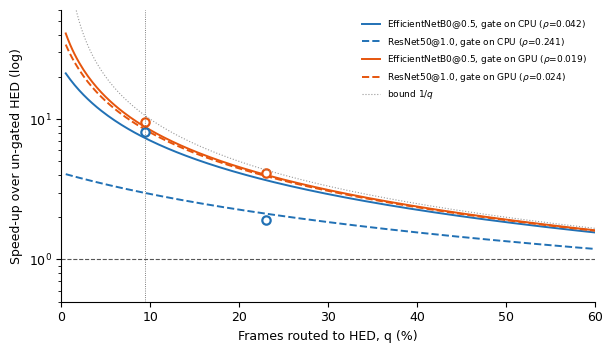

In [ ]:
BGR = [cv2.cvtColor(np.clip(im, 0, 255).astype(np.uint8), cv2.COLOR_RGB2BGR) for im in X]
N_E2E = len(X) if not SMOKE_TEST else 12
e2e = []
for cfg_ in dict.fromkeys([BEST, REF]):
    b, s, st_ = cfg_
    oof, _, taus = OOF[(b, s, st_, CONFIG["CV_SEEDS"][0])]
    route = (oof >= taus[1.0])[:N_E2E]
    head = Head(st_).fit(FEATS[(b, s)][0], FEATS[(b, s)][1], y)        # deployed head (timing only)
    Xs = resize_batch(X[:N_E2E], s)
    for dev in DEVICES:
        with tf.device(f"/{dev}:0"):
            m = build_extractor(b, s)
            fwd = make_fwd(m)
            for _ in range(CONFIG["LAT_WARMUP"]):
                head.score(fwd(tf.constant(Xs[:1])).numpy())
            t_tot = []
            for i in range(N_E2E):
                t = time.perf_counter()
                head.score(fwd(tf.constant(Xs[i:i + 1])).numpy())
                if route[i]:
                    hed_forward(hed, BGR[i])
                t_tot.append(time.perf_counter() - t)
        keras.backend.clear_session()
        L_pipe = float(np.mean(t_tot)); q_ = float(route.mean()); rho_ = rho_of(b, s, dev)
        e2e.append({"config": f"{b}@{s} {st_}", "gate_device": dev, "q": q_, "rho": rho_,
                    "L_pipeline_s": L_pipe, "FPS": 1 / L_pipe, "S_measured": L_HED / L_pipe, "S_predicted": 1 / (rho_ + q_)})
e2e_df = pd.DataFrame(e2e)
e2e_df["model_error_%"] = 100 * (e2e_df.S_predicted - e2e_df.S_measured) / e2e_df.S_measured
save_table(e2e_df.round(4), "end_to_end")
record("end_to_end", e2e_df.to_dict(orient="records"))

fig, ax = plt.subplots(figsize=(6.2, 3.6))
qq = np.linspace(0.005, 1, 400)
for dev, col in zip(DEVICES, ["#2171b5", "#e6550d"]):
    for cfg_, ls in zip(dict.fromkeys([BEST, REF]), ["-", "--"]):
        r_ = rho_of(cfg_[0], cfg_[1], dev)
        ax.plot(100 * qq, 1 / (r_ + qq), color=col, ls=ls, lw=1.4, label=f"{cfg_[0]}@{cfg_[1]}, gate on {dev} ($\\rho$={r_:.3f})")
for _, r in e2e_df.iterrows():
    ax.plot(100 * r.q, r.S_measured, "o", mfc="white", mec="#2171b5" if r.gate_device == "CPU" else "#e6550d", mew=1.6)
ax.plot(100 * qq, 1 / qq, color="#999999", lw=0.8, ls=":", label=r"bound $1/q$")
ax.axhline(1, color="#555555", lw=0.8, ls="--"); ax.axvline(100 * PI, color="#555555", lw=0.6, ls=":")
ax.set_yscale("log"); ax.set_xlim(0, min(100, max(60, 100 * e2e_df.q.max() + 5))); ax.set_ylim(0.5, 60)
ax.set_xlabel("Frames routed to HED, q (%)"); ax.set_ylabel("Speed-up over un-gated HED (log)")
ax.legend(frameon=False, fontsize=6.5); fig.tight_layout(); save_fig(fig, "fig_speedup_model_validation"); plt.show()

## 12. Legacy fine-tuned ResNet50 gate: effect of re-selecting the threshold
Uses the per-frame scores saved by `MLWA_publication_ready_notebook_v2` (original split). The threshold is re-selected on the validation scores with the same rule and applied to the test frames.

In [ ]:
vp, tp_ = (os.path.join(CONFIG["LEGACY_V2_TABLES"], f) for f in ("validation_predictions.csv", "test_predictions.csv"))
legacy = None
if os.path.exists(vp) and os.path.exists(tp_):
    v, t = pd.read_csv(vp), pd.read_csv(tp_)
    tau_star = select_tau(v.prob.values, v.label.values, 1.0)
    rows = []
    for name, tau in [("fixed 0.35", CONFIG["LEGACY_TAU"]), ("fixed 0.5", 0.5), ("validation-selected", tau_star)]:
        for split, d in [("validation", v), ("test", t)]:
            dec = d.prob.values >= tau; yy = d.label.values
            rows.append({"threshold": name, "tau": round(float(tau), 4), "split": split,
                         "recall": (dec & (yy == 1)).sum() / max(yy.sum(), 1), "FP": int((dec & (yy == 0)).sum()),
                         "fpr": (dec & (yy == 0)).sum() / (yy == 0).sum(), "q": dec.mean()})
    legacy = pd.DataFrame(rows)
    save_table(legacy.round(4), "legacy_gate_threshold")
    record("legacy_threshold", legacy.to_dict(orient="records"))
else:
    print("v2 prediction tables not found - section skipped.")

,threshold,tau,split,recall,FP,fpr,q
0,fixed 0.35,0.3500,validation,1.0,62,0.8052,0.8235
1,fixed 0.35,0.3500,test,1.0,1,0.1000,0.1818
2,fixed 0.5,0.5000,validation,1.0,10,0.1299,0.2118
3,fixed 0.5,0.5000,test,1.0,0,0.0000,0.0909
4,validation-selected,0.6369,validation,1.0,0,0.0000,0.0941
5,validation-selected,0.6369,test,1.0,0,0.0000,0.0909


[saved] tables/legacy_gate_threshold.csv


## 13. Error analysis: hardest frames of the best configuration
Background frames with the highest scores and joint frames with the lowest scores (out-of-fold, repeat 0).

[saved] figures/fig_hardest_frames.png/.pdf


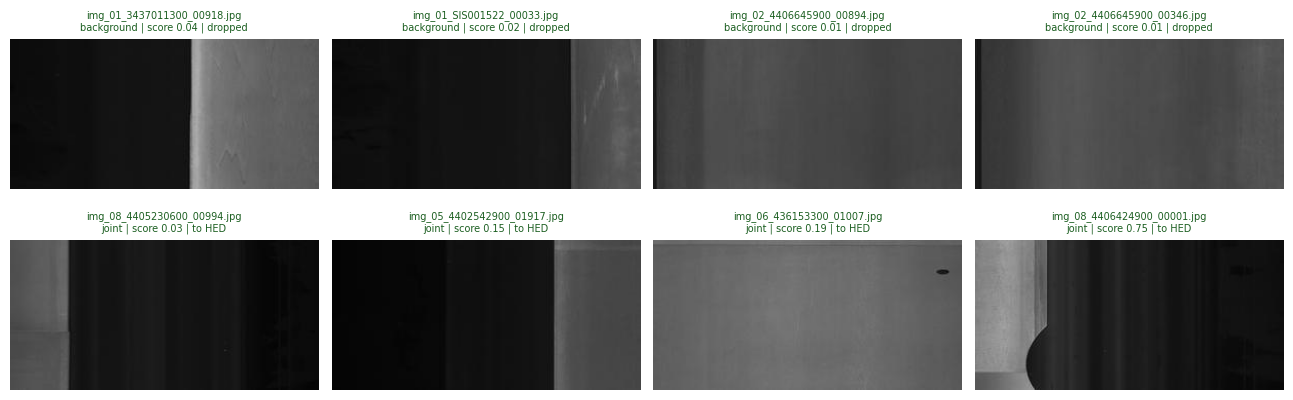

In [ ]:
b, s, st_ = BEST
oof, _, taus = OOF[(b, s, st_, CONFIG["CV_SEEDS"][0])]
neg_i = np.argsort(-np.where(y == 0, oof, -np.inf))[:4]; pos_i = np.argsort(np.where(y == 1, oof, np.inf))[:4]
fig, axes = plt.subplots(2, 4, figsize=(13, 4.4))
for ax, i in zip(axes.ravel(), list(neg_i) + list(pos_i)):
    ax.imshow(cv2.cvtColor(cv2.imread(paths[i]), cv2.COLOR_BGR2RGB)); ax.axis("off")
    routed = oof[i] >= taus[1.0][i]
    ax.set_title(f"{meta.file[i]}\n{'joint' if y[i] else 'background'} | score {oof[i]:.2f} | {'to HED' if routed else 'dropped'}",
                 fontsize=7, color="#b03a2e" if routed != bool(y[i]) else "#1b5e20")
fig.tight_layout(); save_fig(fig, "fig_hardest_frames"); plt.show()

## 14. Export
`overleaf/results_macros_v3.tex` (numbers for the manuscript), figures, `results_summary_v3.json`, and `overleaf_v3.zip`.

In [ ]:
def f3(x, nd=3):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{nd}f}"
def tex_name(b, s, st_):
    return f"{b}@{s} / {st_}".replace("_", r"\_")
M = {}
bm, bs = cv_mean.loc[BEST], cv_sd.loc[BEST]; rm, rs = cv_mean.loc[REF], cv_sd.loc[REF]
M.update({"NFrames": str(len(y)), "NJoints": str(int(y.sum())), "NRecordings": str(meta.recording.nunique()),
          "NStations": str(meta.station.nunique()), "JointRate": f"{100 * PI:.1f}",
          "NFolds": str(CONFIG["N_FOLDS"]), "NRepeats": str(len(CONFIG["CV_SEEDS"])),
          "LHedCPUms": f"{1e3 * L_HED:.0f}", "HedGFLOPs": f"{hed_flops / 1e9:.1f}",
          "BestName": tex_name(*BEST), "RefName": tex_name(*REF),
          "BestPRAUC": f3(bm.pr_auc), "BestFPRRfull": f3(bm.fpr_at_r100), "BestRecall": f"{100 * bm.recall_r100:.1f}",
          "BestRecallSD": f"{100 * bs.recall_r100:.1f}", "BestFPR": f"{100 * bm.fpr_r100:.1f}", "BestQ": f"{100 * bm.q_r100:.1f}",
          "BestSCPU": f"{bm.S_CPU_r100:.1f}", "RefPRAUC": f3(rm.pr_auc), "RefRecall": f"{100 * rm.recall_r100:.1f}",
          "RefFPR": f"{100 * rm.fpr_r100:.1f}", "RefQ": f"{100 * rm.q_r100:.1f}", "RefSCPU": f"{rm.S_CPU_r100:.1f}",
          "BestRhoCPU": f3(rho_of(BEST[0], BEST[1], "CPU")), "RefRhoCPU": f3(rho_of(REF[0], REF[1], "CPU"))})
if "GPU" in DEVICES:
    M.update({"BestSGPU": f"{bm.S_GPU_r100:.1f}", "RefSGPU": f"{rm.S_GPU_r100:.1f}",
              "BestRhoGPU": f3(rho_of(BEST[0], BEST[1], "GPU")), "RefRhoGPU": f3(rho_of(REF[0], REF[1], "GPU"))})
for _, r in e2e_df.iterrows():
    key = ("Best" if r.config == f"{BEST[0]}@{BEST[1]} {BEST[2]}" else "Ref") + r.gate_device
    M.update({f"EtoE{key}S": f"{r.S_measured:.1f}", f"EtoE{key}Spred": f"{r.S_predicted:.1f}",
              f"EtoE{key}FPS": f"{r.FPS:.1f}", f"EtoE{key}Err": f"{r['model_error_%']:.0f}"})
gb = rob_df.set_index(["config", "protocol"])
cfgname = f"{BEST[0]}@{BEST[1]} {BEST[2]}"
for proto, key in [("frame-level 5-fold", "Frame"), ("group-level 5-fold", "Group"), ("leave-one-station-out", "Station")]:
    if (cfgname, proto) in gb.index:
        M[f"Leak{key}FPR"] = f"{100 * gb.loc[(cfgname, proto)].fpr_r100:.1f}"
        M[f"Leak{key}Recall"] = f"{100 * gb.loc[(cfgname, proto)].recall_r100:.1f}"
if legacy is not None:
    lg = legacy.set_index(["threshold", "split"])
    M.update({"LegacyTauStar": f3(lg.loc[("validation-selected", "validation")].tau),
              "LegacyValFPfixed": str(lg.loc[("fixed 0.35", "validation")].FP), "LegacyValFPstar": str(lg.loc[("validation-selected", "validation")].FP),
              "LegacyTestFPfixed": str(lg.loc[("fixed 0.35", "test")].FP), "LegacyTestFPstar": str(lg.loc[("validation-selected", "test")].FP)})

lines = [f"%% Generated {ENV['timestamp_utc']} UTC | TF {ENV['tensorflow']} | OpenCV {ENV['opencv']} | CPU {ENV['cpu_model']} | GPU {ENV['gpu_model'] or 'none'}"]
lines += [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in M.items()]
open(os.path.join(DIRS["overleaf"], "results_macros_v3.tex"), "w").write("\n".join(lines) + "\n")
os.makedirs(os.path.join(DIRS["overleaf"], "figures"), exist_ok=True)
for f in os.listdir(DIRS["figures"]):
    if f.endswith(".png"):
        shutil.copy(os.path.join(DIRS["figures"], f), os.path.join(DIRS["overleaf"], "figures", f))
for f in ["complexity", "latency_cpu_gpu", "best_per_gate", "strategies_on_best_gate", "robustness_protocols", "end_to_end"]:
    if os.path.exists(os.path.join(DIRS["tables"], f + ".csv")):
        shutil.copy(os.path.join(DIRS["tables"], f + ".csv"), os.path.join(DIRS["overleaf"], f + ".csv"))
shutil.make_archive(os.path.join(RD, "overleaf_v3"), "zip", DIRS["overleaf"])
record("latex_macros", M)
json.dump({"environment": ENV, "config": CONFIG, "results": RESULTS}, open(os.path.join(RD, "results_summary_v3.json"), "w"),
          indent=2, default=lambda o: o.item() if hasattr(o, "item") else (list(o) if isinstance(o, tuple) else str(o)))
print("\n".join(lines))
print("\nSaved:", os.path.join(RD, "overleaf_v3.zip"), "and results_summary_v3.json")

%% Generated 2026-10-17 10:24:00 UTC | TF 2.21.0 | OpenCV 4.14.0 | CPU Intel(R) Xeon(R) CPU @ 2.00GHz | GPU Tesla T4, 15360 MiB
\newcommand{\NFrames}{309}
\newcommand{\NJoints}{29}
\newcommand{\NRecordings}{80}
\newcommand{\NStations}{7}
\newcommand{\JointRate}{9.4}
\newcommand{\NFolds}{5}
\newcommand{\NRepeats}{3}
\newcommand{\LHedCPUms}{476}
\newcommand{\HedGFLOPs}{48.7}
\newcommand{\BestName}{EfficientNetB0@0.5 / LR-weighted}
\newcommand{\RefName}{ResNet50@1.0 / Focal-weighted}
\newcommand{\BestPRAUC}{1.000}
\newcommand{\BestFPRRfull}{0.001}
\newcommand{\BestRecall}{100.0}
\newcommand{\BestRecallSD}{0.0}
\newcommand{\BestFPR}{0.4}
\newcommand{\BestQ}{9.7}
\newcommand{\BestSCPU}{7.2}
\newcommand{\RefPRAUC}{0.985}
\newcommand{\RefRecall}{100.0}
\newcommand{\RefFPR}{12.9}
\newcommand{\RefQ}{21.0}
\newcommand{\RefSCPU}{2.3}
\newcommand{\BestRhoCPU}{0.042}
\newcommand{\RefRhoCPU}{0.241}
\newcommand{\BestSGPU}{8.6}
\newcommand{\RefSGPU}{4.6}
\newcommand{\BestRhoGPU}{0.019}
\newcommand{\Re